# 01 — Préparation des données (TON_IoT Network)

**Responsable : Membre 1** · Entrée : `data/train_test_network.csv` · Sorties : `data/processed/*.parquet`, `config.json`

Ce notebook est le **socle commun** des 5 membres : tous les modèles (notebooks 02 à 05) lisent exactement les mêmes
jeux *train / validation / test* produits ici.

| Notebook | Tâche | Modèle | Membre |
|---|---|---|---|
| 01 | Préparation, EDA, équilibrage | — | 1 |
| 02 | Détection d'anomalies (`label`) | Random Forest | 2 |
| 03 | Détection d'anomalies (`label`) | SVM (linéaire + RBF) | 3 |
| 04 | Prédiction du type (`type`) | Random Forest Regressor | 4 |
| 05 | Prédiction du type (`type`) | XGBoost Regressor | 5 |
| 06 | Tableau comparatif final | tous | tous |

## Plan de préparation (ordre strict, anti-fuite)

1. Chargement et contrôle qualité (valeurs `-` = manquantes, doublons, conflits d'étiquettes)
2. Analyse exploratoire (EDA)
3. Feature engineering (stateless, ligne par ligne)
4. Nettoyage : suppression de colonnes, **déduplication**, gestion des outliers
5. **Split stratifié 60 / 20 / 20** (avant toute statistique apprise)
6. Sélection de variables (sur le **train seulement**)
7. Étude de l'**équilibrage des données** (sur le train seulement)
8. Sauvegarde des artefacts

In [1]:
import sys, json, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
report = {}  # résumé qualité sauvegardé à la fin

## 1. Chargement et contrôle qualité

Zeek (l'outil qui a produit ce jeu) écrit `-` quand une valeur est **absente**. Pandas ne le reconnaît pas comme
manquant : un `isna().sum()` naïf affiche donc **0 valeur manquante**, ce qui est faux. `load_raw()` convertit `-` en `NaN`.

In [2]:
raw = U.load_raw()
print(f"Dimensions : {raw.shape[0]:,} lignes x {raw.shape[1]} colonnes")
print(raw.dtypes.value_counts().to_string())
display(raw.head(3))

Dimensions : 211,043 lignes x 44 colonnes
str        27
int64      15
float64     1
int8        1


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_query,dns_qclass,dns_qtype,dns_rcode,dns_AA,dns_RD,dns_RA,dns_rejected,ssl_version,ssl_cipher,ssl_resumed,ssl_established,ssl_subject,ssl_issuer,http_trans_depth,http_method,http_uri,http_version,http_request_body_len,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,NaN,290.3715,101568,2592,OTH,0,108,108064,31,3832,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.0001,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.0001,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor


22 colonnes avec des valeurs manquantes (après conversion de '-')


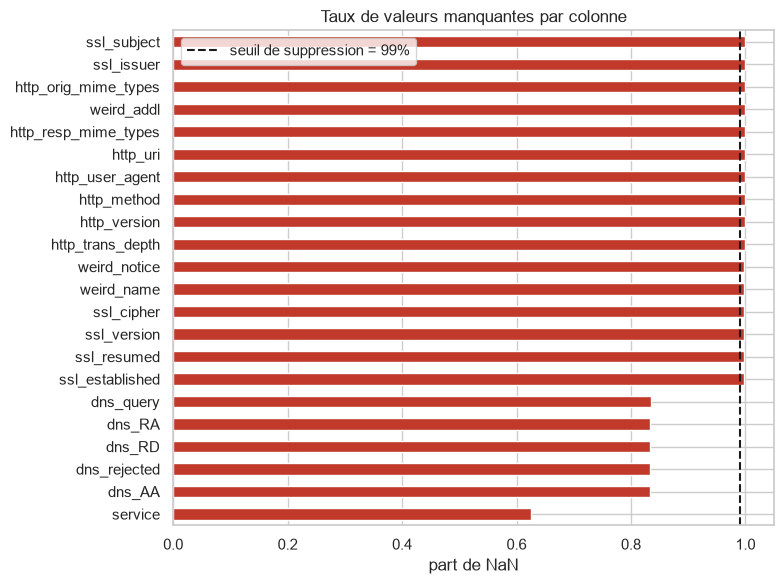

In [3]:
miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f"{len(miss)} colonnes avec des valeurs manquantes (après conversion de '-')")
fig, ax = plt.subplots(figsize=(8, 6))
miss.sort_values().plot(kind="barh", ax=ax, color="#c0392b")
ax.axvline(U.MAX_MISSING_RATE, color="k", ls="--", label=f"seuil de suppression = {U.MAX_MISSING_RATE:.0%}")
ax.set(title="Taux de valeurs manquantes par colonne", xlabel="part de NaN")
ax.legend(); plt.tight_layout(); U.savefig(fig, "01_missing_rates"); plt.show()
report["n_rows_raw"] = len(raw)

In [4]:
# Doublons : exacts, et "conflits" (mêmes variables explicatives mais types différents)
feat_all = [c for c in raw.columns if c not in ("label", "type")]
dup_exact = raw.duplicated().sum()
print(f"Doublons exacts : {dup_exact:,} ({dup_exact/len(raw):.1%})")
print("Répartition par type :"); print(raw[raw.duplicated()]["type"].value_counts().to_string())
h = pd.util.hash_pandas_object(raw[feat_all], index=False)
n_types_per_hash = raw.assign(_h=h).groupby("_h")["type"].nunique()
print(f"\nLignes à variables identiques mais types différents (conflits) : {(n_types_per_hash > 1).sum():,} groupes")
report["dup_exact_raw"] = int(dup_exact)

Doublons exacts : 20,569 (9.7%)
Répartition par type :
type
normal        7960
ransomware    5265
xss           4863
backdoor      1289
dos           1008
password       139
injection       36
ddos             7
mitm             2

Lignes à variables identiques mais types différents (conflits) : 0 groupes


## 2. Analyse exploratoire (EDA)

Deux cibles **différentes** : `label` (binaire : 0 normal / 1 attaque) et `type` (10 classes). `label` se déduit
entièrement de `type` (vérifié ci-dessous) : `type` ne doit donc **jamais** être une variable explicative.

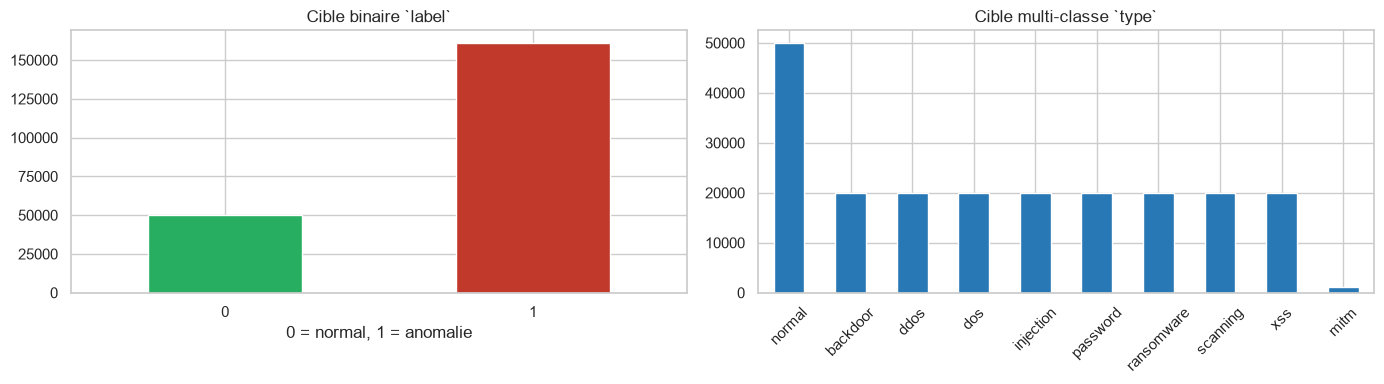

label,0,1
type,,
backdoor,0,20000
ddos,0,20000
dos,0,20000
injection,0,20000
mitm,0,1043
normal,50000,0
password,0,20000
ransomware,0,20000
scanning,0,20000


OK : label = (type != 'normal'). `type` est exclu des variables explicatives.
Part des attaques : 76.3% | classe la plus rare (mitm) : 0.49%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw["label"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#27ae60", "#c0392b"])
axes[0].set(title="Cible binaire `label`", xlabel="0 = normal, 1 = anomalie"); axes[0].tick_params(axis="x", rotation=0)
raw["type"].value_counts().plot(kind="bar", ax=axes[1], color="#2878b5")
axes[1].set(title="Cible multi-classe `type`", xlabel=""); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); U.savefig(fig, "01_targets"); plt.show()

ct = pd.crosstab(raw["type"], raw["label"]); display(ct)
assert ct.loc["normal", 1] == 0 and ct.drop(index="normal")[0].sum() == 0, "label n'est pas déterminé par type"
print("OK : label = (type != 'normal'). `type` est exclu des variables explicatives.")
print(f"Part des attaques : {raw['label'].mean():.1%} | classe la plus rare (mitm) : {(raw['type']=='mitm').mean():.2%}")

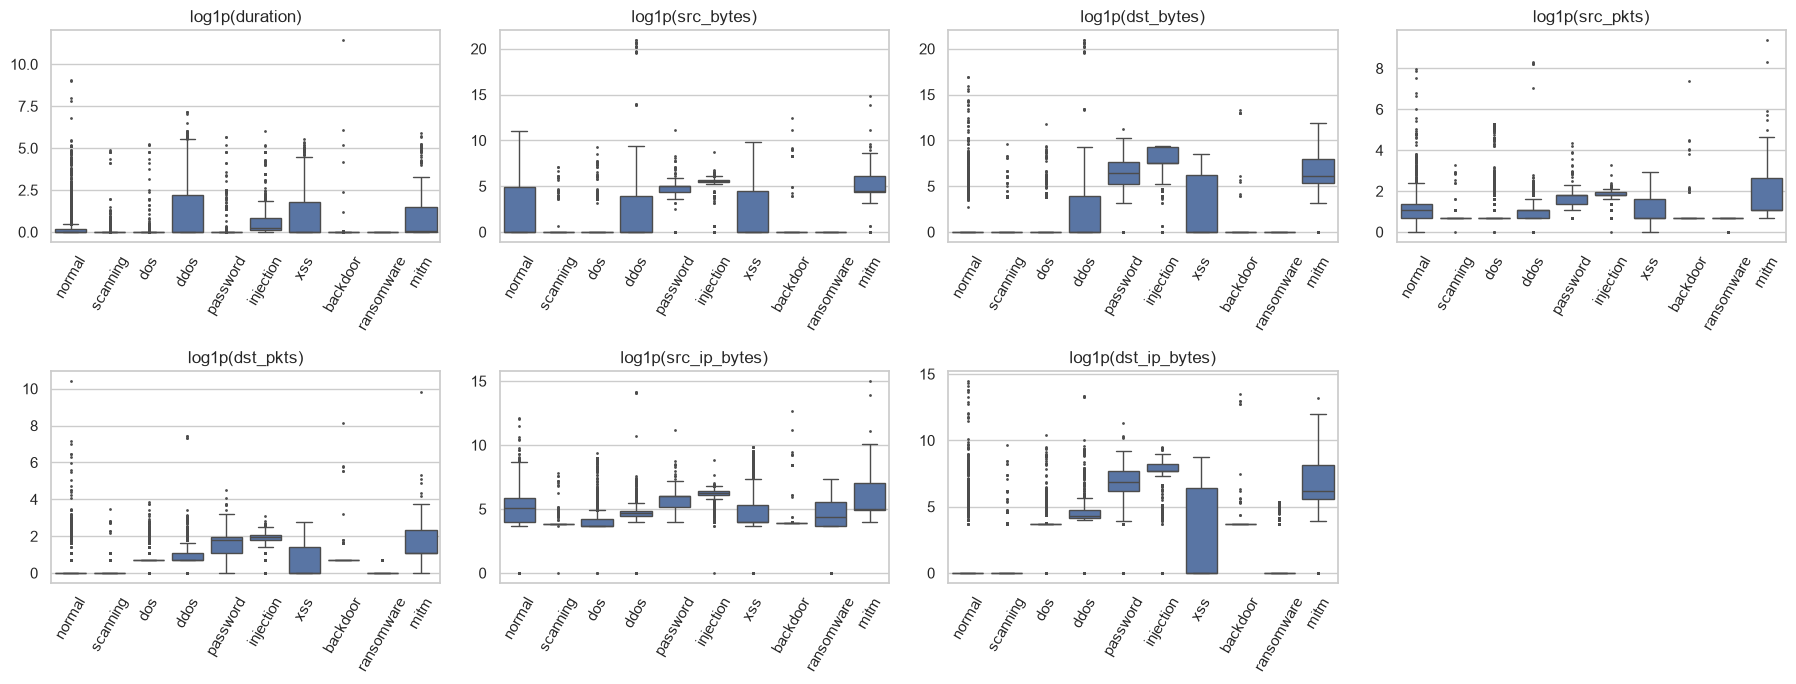

In [6]:
num_eda = ["duration", "src_bytes", "dst_bytes", "src_pkts", "dst_pkts", "src_ip_bytes", "dst_ip_bytes"]
smp = raw.sample(40000, random_state=U.RANDOM_STATE)
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, c in zip(axes, num_eda):
    sns.boxplot(data=smp.assign(v=np.log1p(smp[c])), x="type", y="v", ax=ax, order=U.TYPE_ORDER, fliersize=1)
    ax.set(title=f"log1p({c})", xlabel="", ylabel=""); ax.tick_params(axis="x", rotation=60)
axes[-1].axis("off"); plt.tight_layout(); U.savefig(fig, "01_numeric_by_type"); plt.show()

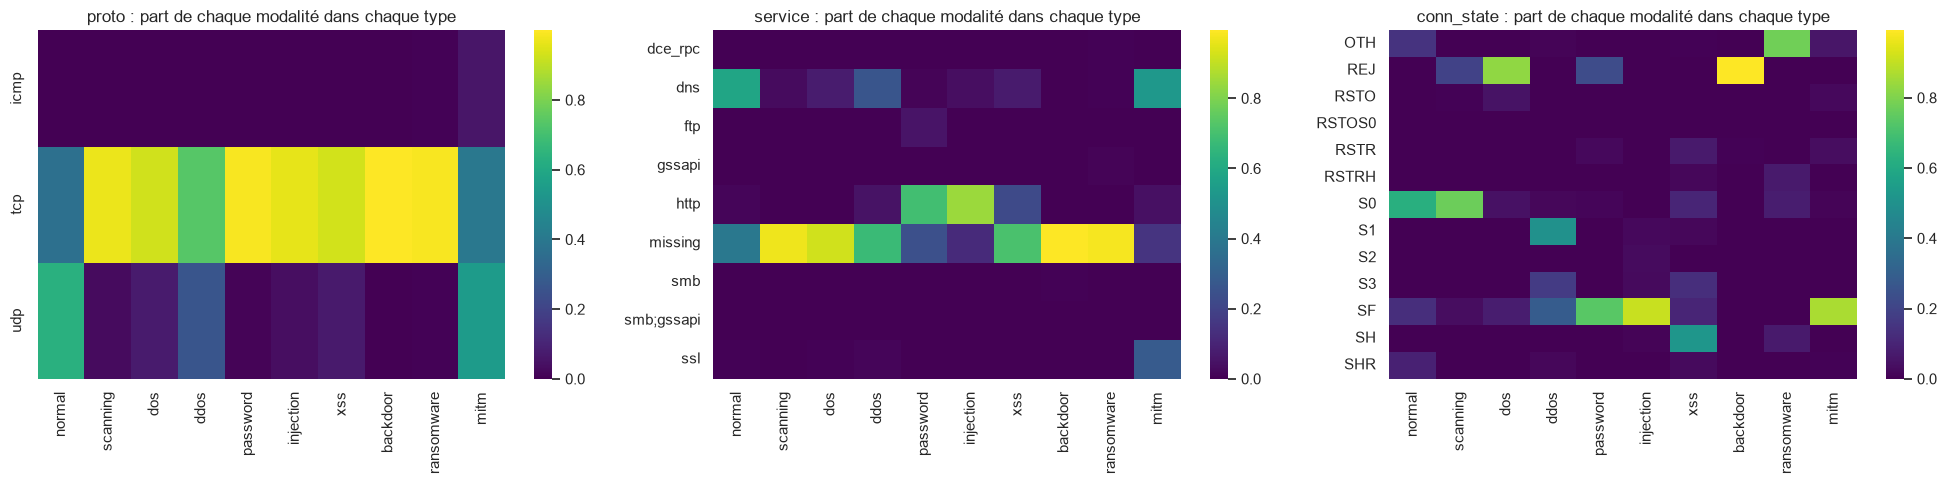

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, ["proto", "service", "conn_state"]):
    t = pd.crosstab(raw[c].fillna("missing"), raw["type"])[U.TYPE_ORDER]
    sns.heatmap(t.div(t.sum(axis=0), axis=1), annot=False, cmap="viridis", ax=ax)
    ax.set(title=f"{c} : part de chaque modalité dans chaque type", xlabel="", ylabel="")
plt.tight_layout(); U.savefig(fig, "01_categorical_by_type"); plt.show()

## 3. Feature engineering

Variables dérivées **ligne par ligne** (aucune statistique globale, donc aucune fuite) :

- **Indicateurs de protocole** `has_dns / has_http / has_ssl / has_weird` : remplacent les colonnes `http_*`, `ssl_*`, `weird_*`
  presque vides (>99 % de NaN) tout en conservant l'information « ce flux contient du HTTP/SSL/… ».
- **Volumes / débits / ratios** : `total_bytes`, `bytes_ratio`, `bytes_per_sec`, `pkts_per_sec`… (les scans et DoS ont des
  signatures de débit très différentes d'un trafic normal).
- **Ports en catégories** (`well_known / registered / ephemeral`) plutôt que 65 535 valeurs.
- **Réseau interne** `src_internal / dst_internal`.

In [8]:
fe = U.engineer_features(raw)
new_cols = [c for c in fe.columns if c not in raw.columns]
print(f"{len(new_cols)} variables créées :", new_cols)
display(fe[new_cols + ["type"]].groupby("type").median(numeric_only=True).round(3).loc[U.TYPE_ORDER])

19 variables créées : ['has_dns', 'has_http', 'has_ssl', 'has_weird', 'total_bytes', 'total_pkts', 'bytes_ratio', 'pkts_ratio', 'bytes_per_pkt_src', 'bytes_per_pkt_dst', 'bytes_per_sec', 'pkts_per_sec', 'ip_overhead_src', 'ip_overhead_dst', 'src_port_bucket', 'dst_port_bucket', 'same_ports', 'src_internal', 'dst_internal']


,has_dns,has_http,has_ssl,has_weird,total_bytes,total_pkts,bytes_ratio,pkts_ratio,bytes_per_pkt_src,bytes_per_pkt_dst,bytes_per_sec,pkts_per_sec,ip_overhead_src,ip_overhead_dst,same_ports,src_internal,dst_internal
type,,,,,,,,,,,,,,,,,
normal,0.0000,0.0000,0.0000,0.0000,122.0000,2.0000,0.0000,2.0000,0.0000,0.0000,88.4440,604.9580,56.0000,0.0000,0.0000,1.0000,1.0000
scanning,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,44.0000,0.0000,0.0000,1.0000,1.0000
dos,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.5000,0.0000,0.0000,0.0000,1752.8480,40.0000,40.0000,1.0000,1.0000,1.0000
ddos,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,0.0000,1.0000,0.0000,0.0000,0.0000,907.3340,112.0000,60.0000,0.0000,1.0000,1.0000
password,0.0000,0.0000,0.0000,0.0000,806.0000,10.0000,0.0800,0.8330,25.5000,108.5000,99793.0160,1821.4940,268.0000,268.0000,0.0000,1.0000,1.0000
injection,0.0000,0.0000,0.0000,0.0000,2492.0000,11.0000,0.0920,0.7140,41.5000,356.5710,9854.9980,39.4160,268.0000,320.0000,0.0000,1.0000,1.0000
xss,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,52.0000,0.0000,0.0000,1.0000,0.0000
backdoor,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.5000,0.0000,0.0000,0.0000,1768.3470,48.0000,40.0000,0.0000,1.0000,1.0000
ransomware,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,76.0000,0.0000,0.0000,1.0000,1.0000


## 4. Nettoyage

### 4.1 Suppression de colonnes
| Règle | Raison |
|---|---|
| `src_ip`, `dst_ip` | identifiants d'hôtes : le modèle mémoriserait l'environnement du banc d'essai |
| `label`, `type` hors cible | fuite directe |
| > 99 % de NaN | aucune information exploitable (les `has_*` conservent le signal) |
| texte à cardinalité > 50 | one-hot ingérable et mémorisation (`dns_query`, `http_uri`, …) |

In [9]:
drop_reason = {}
for c in U.ID_COLUMNS: drop_reason[c] = "identifiant d'hôte"
high_missing = [c for c in fe.columns if fe[c].isna().mean() > U.MAX_MISSING_RATE]
for c in high_missing: drop_reason[c] = f"> {U.MAX_MISSING_RATE:.0%} de valeurs manquantes"
obj_cols = [c for c in fe.select_dtypes(include="object").columns if c not in ("type",) + tuple(drop_reason)]
for c in obj_cols:
    if fe[c].nunique() > 50: drop_reason[c] = f"cardinalité élevée ({fe[c].nunique()} modalités)"
display(pd.Series(drop_reason, name="raison").to_frame())
clean = fe.drop(columns=list(drop_reason))
print("Colonnes conservées :", clean.shape[1] - 2, "(hors label/type)")

,raison
src_ip,identifiant d'hôte
dst_ip,identifiant d'hôte
ssl_version,> 99% de valeurs manquantes
ssl_cipher,> 99% de valeurs manquantes
ssl_resumed,> 99% de valeurs manquantes
ssl_established,> 99% de valeurs manquantes
ssl_subject,> 99% de valeurs manquantes
ssl_issuer,> 99% de valeurs manquantes
http_trans_depth,> 99% de valeurs manquantes
http_method,> 99% de valeurs manquantes


Colonnes conservées : 42 (hors label/type)


### 4.2 Déduplication — **avant** le split

Les lignes identiques sur les variables du modèle sont très nombreuses (flux répétitifs : scans, REJ, DNS…). Si on les laisse,
une même ligne tombe à la fois dans le *train* et dans le *test* : les scores sont **gonflés** par simple mémorisation.
On supprime donc les doublons (variables + cibles), puis on retire les **conflits** (mêmes variables, types différents) qui
sont par nature indécidables pour n'importe quel modèle.

In [10]:
feat_model = [c for c in clean.columns if c not in ("label", "type")]
n0 = len(clean)
clean = clean.drop_duplicates()
n1 = len(clean)
hh = pd.util.hash_pandas_object(clean[feat_model], index=False)
conflict = clean.assign(_h=hh).groupby("_h")["type"].transform("nunique") > 1
n_conf = int(conflict.sum())
clean = clean[~conflict.values].reset_index(drop=True)
print(f"Lignes initiales            : {n0:,}")
print(f"Doublons supprimés          : {n0-n1:,}")
print(f"Lignes en conflit supprimées: {n_conf:,}")
print(f"Lignes finales              : {len(clean):,}")
display(pd.concat([raw["type"].value_counts().rename("avant"), clean["type"].value_counts().rename("après")], axis=1).loc[U.TYPE_ORDER])
report.update(n_rows_dedup=int(n1), n_conflicts=n_conf, n_rows_clean=len(clean))

Lignes initiales            : 211,043
Doublons supprimés          : 27,477
Lignes en conflit supprimées: 12
Lignes finales              : 183,554


,avant,après
type,,
normal,50000,41935
scanning,20000,18615
dos,20000,14675
ddos,20000,19985
password,20000,19847
injection,20000,19959
xss,20000,14522
backdoor,20000,18710
ransomware,20000,14266


### 4.3 Valeurs aberrantes (outliers)

Les volumes d'octets/paquets ont des **queues très lourdes** (max ≈ 4·10⁹ octets pour une médiane de 0). En réseau, ces valeurs
extrêmes **sont** le signal (DoS, exfiltration) : on ne supprime aucune ligne. On applique **`log1p`** (dans le pipeline, appris sans
fuite car sans paramètre) — indispensable pour le SVM, neutre pour les arbres.

,skew,% hors IQR×1.5,log_appliqué
dst_ip_bytes,414.7044,22.1286,True
http_response_body_len,380.2972,0.1460,True
bytes_per_sec,300.8076,19.9178,True
bytes_ratio,285.6870,18.0530,True
dst_pkts,271.5067,13.2190,True
missed_bytes,235.6795,1.6039,True
total_pkts,235.0951,7.2742,True
pkts_ratio,226.1594,16.1364,True
http_request_body_len,160.1375,0.0087,True
src_ip_bytes,154.5153,11.1292,True


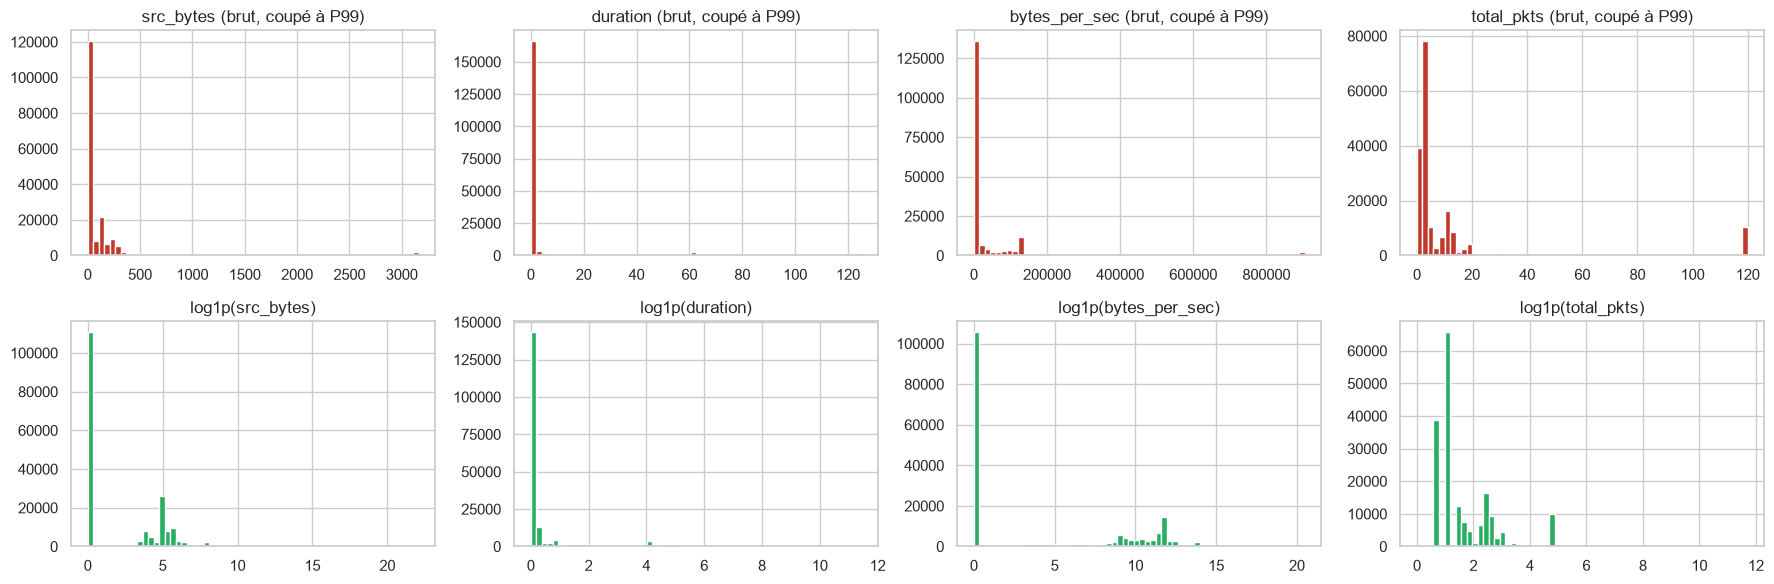

In [11]:
num_now = [c for c in clean.select_dtypes(include="number").columns if c not in ("label",)]
q1, q3 = clean[num_now].quantile(.25), clean[num_now].quantile(.75); iqr = q3 - q1
stats = pd.DataFrame({
    "skew": clean[num_now].skew(),
    "% hors IQR×1.5": ((clean[num_now].lt(q1 - 1.5*iqr)) | (clean[num_now].gt(q3 + 1.5*iqr))).mean() * 100,
    "log_appliqué": [c in U.LOG_COLUMNS for c in num_now],
}).sort_values("skew", ascending=False)
display(stats.head(15))
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for j, c in enumerate(["src_bytes", "duration", "bytes_per_sec", "total_pkts"]):
    v = clean[c]; axes[0, j].hist(v.clip(upper=v.quantile(.99)), bins=60, color="#c0392b"); axes[0, j].set_title(f"{c} (brut, coupé à P99)")
    axes[1, j].hist(np.log1p(v), bins=60, color="#27ae60"); axes[1, j].set_title(f"log1p({c})")
plt.tight_layout(); U.savefig(fig, "01_outliers_log1p"); plt.show()

## 5. Split stratifié 60 / 20 / 20

Le découpage est fait **avant** toute sélection de variables ou apprentissage. La stratification sur `type` garantit que la classe
rare `mitm` est présente dans chaque jeu (et donc aussi que `label` est stratifié, puisqu'il dérive de `type`).
- **Train (60 %)** : apprentissage, validation croisée, rééchantillonnage
- **Validation (20 %)** : choix des hyper-paramètres et du **seuil** de décision
- **Test (20 %)** : évalué **une seule fois**, à la fin

In [12]:
from sklearn.model_selection import train_test_split
y_all = clean[["label", "type"]].copy(); y_all["type_code"] = y_all["type"].map(U.TYPE_TO_CODE).astype("int8")
X_all = clean.drop(columns=["label", "type"])
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all["type"], random_state=U.RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp["type"], random_state=U.RANDOM_STATE)
for df_ in (X_train, X_valid, X_test, y_train, y_valid, y_test): df_.reset_index(drop=True, inplace=True)
dist = pd.concat({n: y["type"].value_counts(normalize=True) for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]}, axis=1).loc[U.TYPE_ORDER]
display(dist.mul(100).round(2).assign(**{"effectif train": y_train["type"].value_counts().reindex(U.TYPE_ORDER)}))
print({n: len(y) for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]})
print("Part d'attaques (label=1) :", {n: round(y["label"].mean(), 4) for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]})

,train,valid,test,effectif train
type,,,,
normal,22.8500,22.8500,22.8500,25161
scanning,10.1400,10.1400,10.1400,11169
dos,7.9900,7.9900,7.9900,8805
ddos,10.8900,10.8900,10.8900,11991
password,10.8100,10.8100,10.8100,11908
injection,10.8700,10.8700,10.8700,11975
xss,7.9100,7.9100,7.9100,8713
backdoor,10.1900,10.1900,10.1900,11226
ransomware,7.7700,7.7700,7.7700,8560


{'train': 110132, 'valid': 36711, 'test': 36711}
Part d'attaques (label=1) : {'train': np.float64(0.7715), 'valid': np.float64(0.7715), 'test': np.float64(0.7715)}


## 6. Sélection de variables (calculée sur le train uniquement)

Méthodes **filtre** en trois étapes :
1. variance nulle (constantes) ;
2. **corrélation de Spearman** : parmi deux variables numériques de |ρ| > 0,97, on supprime la dérivée (redondance, instabilité du SVM) ;
3. **information mutuelle** avec chaque cible : on supprime les variables sans lien avec **aucune** des deux cibles.

La sélection **embarquée** (importances Random Forest / XGBoost, permutation) est faite dans les notebooks 02 à 05.

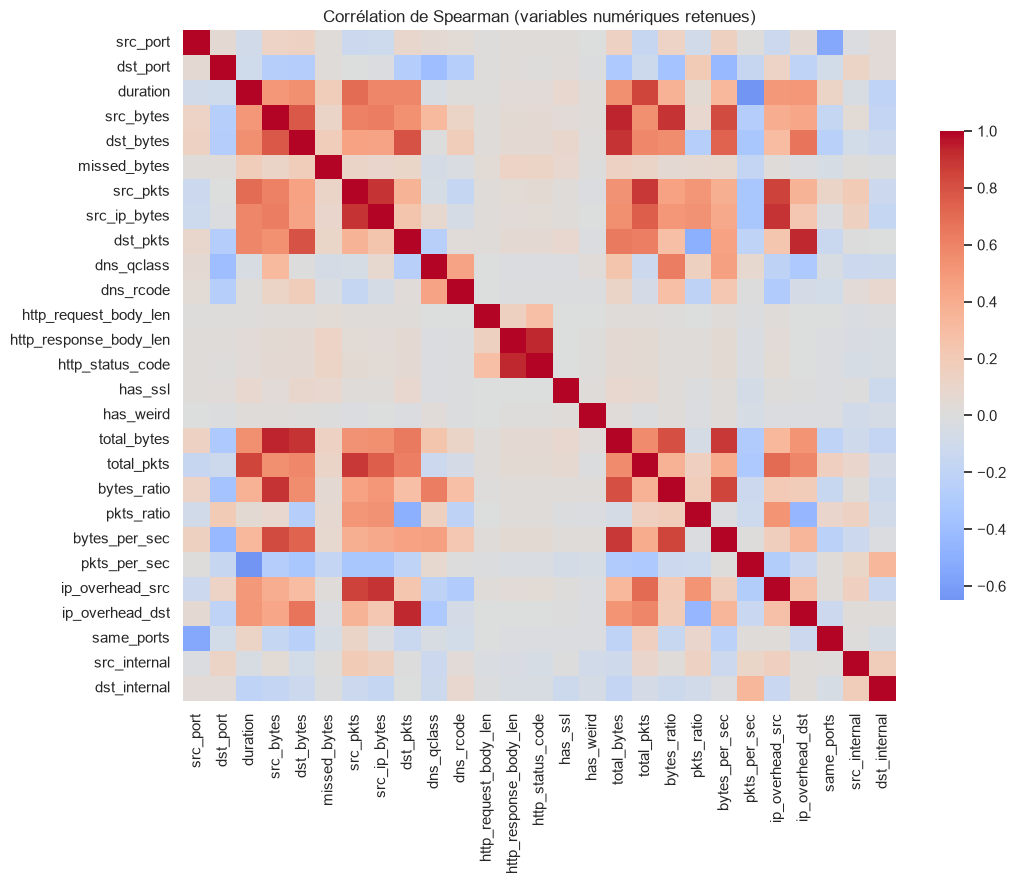

,raison
dst_ip_bytes,corrélée à dst_pkts (|rho|=0.973)
dns_qtype,corrélée à dns_qclass (|rho|=0.995)
has_dns,corrélée à dns_qclass (|rho|=0.998)
has_http,corrélée à http_status_code (|rho|=0.979)
bytes_per_pkt_src,corrélée à src_bytes (|rho|=0.978)
bytes_per_pkt_dst,corrélée à dst_bytes (|rho|=0.998)


In [13]:
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
removed = {}
# 1) variance nulle
for c in X_train.columns:
    if X_train[c].nunique(dropna=False) <= 1: removed[c] = "constante sur le train"
num_cols = [c for c in num_cols if c not in removed]; cat_cols = [c for c in cat_cols if c not in removed]
# 2) corrélation
smp = X_train[num_cols].sample(min(50000, len(X_train)), random_state=U.RANDOM_STATE)
corr = smp.corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
for c in upper.columns:
    partners = upper.index[upper[c] > 0.97].tolist()
    if partners and c not in removed: removed[c] = f"corrélée à {partners[0]} (|rho|={upper.loc[partners[0], c]:.3f})"
num_cols = [c for c in num_cols if c not in removed]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(smp[num_cols].corr(method="spearman"), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Corrélation de Spearman (variables numériques retenues)"); plt.tight_layout(); U.savefig(fig, "01_correlation"); plt.show()
display(pd.Series(removed, name="raison").to_frame())

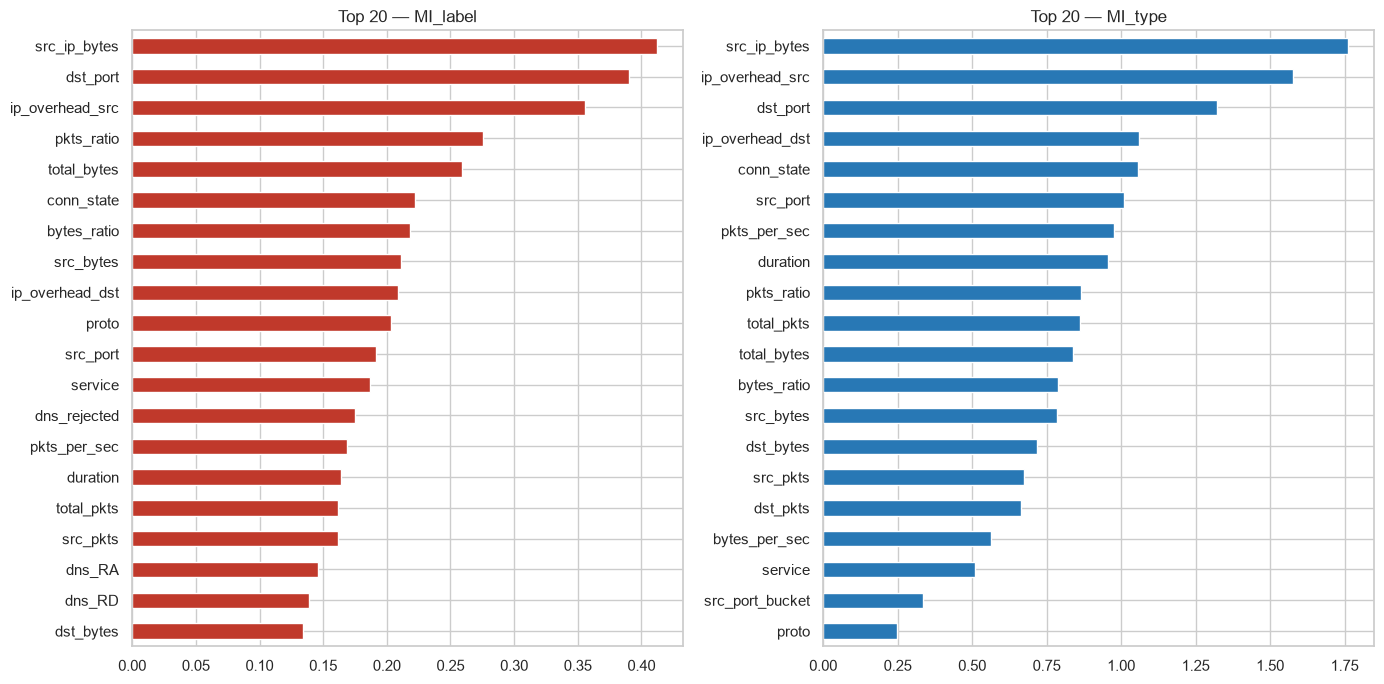

Variables retenues : 24 numériques + 9 catégorielles = 33
Supprimées par MI : ['http_response_body_len', 'has_ssl', 'http_request_body_len']


In [14]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
idx = X_train.sample(min(30000, len(X_train)), random_state=U.RANDOM_STATE).index
Xm = X_train.loc[idx, num_cols + cat_cols].copy()
Xm[num_cols] = Xm[num_cols].fillna(Xm[num_cols].median())
Xm[cat_cols] = OrdinalEncoder().fit_transform(Xm[cat_cols].fillna("missing"))
disc = np.array([c in cat_cols for c in Xm.columns])
mi = pd.DataFrame({
    "MI_label": mutual_info_classif(Xm, y_train.loc[idx, "label"], discrete_features=disc, random_state=U.RANDOM_STATE),
    "MI_type": mutual_info_classif(Xm, y_train.loc[idx, "type"], discrete_features=disc, random_state=U.RANDOM_STATE),
}, index=Xm.columns).sort_values("MI_type", ascending=False)
low = mi[(mi.MI_label < 0.001) & (mi.MI_type < 0.001)].index.tolist()
for c in low: removed[c] = "information mutuelle ~ 0 avec label ET type"
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, color in zip(axes, ["MI_label", "MI_type"], ["#c0392b", "#2878b5"]):
    mi[col].sort_values().tail(20).plot(kind="barh", ax=ax, color=color); ax.set_title(f"Top 20 — {col}")
plt.tight_layout(); U.savefig(fig, "01_mutual_information"); plt.show()
num_cols = [c for c in num_cols if c not in low]; cat_cols = [c for c in cat_cols if c not in low]
print(f"Variables retenues : {len(num_cols)} numériques + {len(cat_cols)} catégorielles = {len(num_cols)+len(cat_cols)}")
print("Supprimées par MI :", low)

## 7. Équilibrage des données

### 7.1 Diagnostic
Deux déséquilibres distincts :
- **Binaire** : la classe *normal* est minoritaire (≈ 20-25 %) — le déséquilibre est **inversé** par rapport à un cas classique, et c'est
  justement la classe « normal » dont les erreurs (faux positifs) coûtent des fausses alertes.
- **Multi-classe** : `mitm` ≈ 0,5 % des lignes (≈ 20× moins que les autres attaques).

### 7.2 Règle d'or
Le rééchantillonnage (SMOTE, sous-échantillonnage…) s'applique **uniquement au train**, et **après** le split. La validation et le test
conservent la distribution réelle. Dans les notebooks 02-05, il est placé **dans** un `Pipeline` imbalanced-learn pour qu'il ne soit
appliqué qu'aux plis d'apprentissage de la validation croisée.

### 7.3 Techniques comparées
| Technique | Principe | Risque |
|---|---|---|
| `class_weight / sample_weight` | pondère la perte, aucune ligne créée | aucun, rapide |
| `RandomUnderSampler` | retire des lignes de la classe majoritaire | perte d'information |
| `RandomOverSampler` | duplique la classe minoritaire | surapprentissage |
| `SMOTE` | crée des points synthétiques par interpolation entre voisins | points irréalistes sur les variables one-hot |

Sonde rapide : Random Forest léger sur un sous-échantillon du train, évalué sur la **validation**.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, matthews_corrcoef, roc_auc_score, recall_score
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import time

pre = U.make_preprocessor(num_cols, cat_cols, scale=False)
sub = X_train.sample(30000, random_state=U.RANDOM_STATE).index
Xs, ys = X_train.loc[sub], y_train.loc[sub]
Xp = pre.fit_transform(Xs); Xv = pre.transform(X_valid)
samplers = {"Aucun": (None, None), "class_weight": (None, "balanced"),
            "RandomUnderSampler": (RandomUnderSampler(random_state=U.RANDOM_STATE), None),
            "RandomOverSampler": (RandomOverSampler(random_state=U.RANDOM_STATE), None),
            "SMOTE": (SMOTE(k_neighbors=5, random_state=U.RANDOM_STATE), None)}
def probe(target):
    rows = []
    for name, (smp_, cw) in samplers.items():
        t0 = time.time(); Xr, yr = (Xp, ys[target]) if smp_ is None else smp_.fit_resample(Xp, ys[target])
        rf = RandomForestClassifier(n_estimators=40, min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=U.RANDOM_STATE).fit(Xr, yr)
        pred = rf.predict(Xv); yv = y_valid[target]
        row = {"stratégie": name, "n_train": Xr.shape[0], "balanced_acc": balanced_accuracy_score(yv, pred), "mcc": matthews_corrcoef(yv, pred)}
        if target == "label":
            row.update(f1_normal=f1_score(yv, pred, pos_label=0), recall_normal=recall_score(yv, pred, pos_label=0), f1_attaque=f1_score(yv, pred))
        else:
            row.update(f1_macro=f1_score(yv, pred, average="macro"), f1_mitm=f1_score(yv, pred, labels=["mitm"], average="macro"),
                       recall_mitm=recall_score(yv, pred, labels=["mitm"], average="macro"))
        row["temps_s"] = time.time() - t0; rows.append(row)
    return pd.DataFrame(rows).set_index("stratégie")
probe_bin = probe("label"); print("Détection binaire (validation)"); display(probe_bin.round(4))
probe_type = probe("type"); print("Prédiction du type, sonde classifieur (validation)"); display(probe_type.round(4))

Détection binaire (validation)


,n_train,balanced_acc,mcc,f1_normal,recall_normal,f1_attaque,temps_s
stratégie,,,,,,,
Aucun,30000,0.9951,0.9914,0.9934,0.9918,0.9980,0.4232
class_weight,30000,0.9963,0.9914,0.9933,0.9951,0.9980,0.3415
RandomUnderSampler,13734,0.9958,0.9888,0.9914,0.9955,0.9974,0.1941
RandomOverSampler,46266,0.9961,0.9923,0.9941,0.9938,0.9983,0.5331
SMOTE,46266,0.9959,0.9920,0.9938,0.9936,0.9982,0.9406


Prédiction du type, sonde classifieur (validation)


,n_train,balanced_acc,mcc,f1_macro,f1_mitm,recall_mitm,temps_s
stratégie,,,,,,,
Aucun,30000,0.9575,0.9799,0.9519,0.6740,0.7356,0.8321
class_weight,30000,0.9777,0.9792,0.9528,0.6828,0.9471,1.0430
RandomUnderSampler,1710,0.9606,0.9523,0.9085,0.4037,0.9519,0.8371
RandomOverSampler,68670,0.9665,0.9810,0.9554,0.6996,0.8173,1.6941
SMOTE,68670,0.9742,0.9805,0.9565,0.7148,0.9038,2.2760


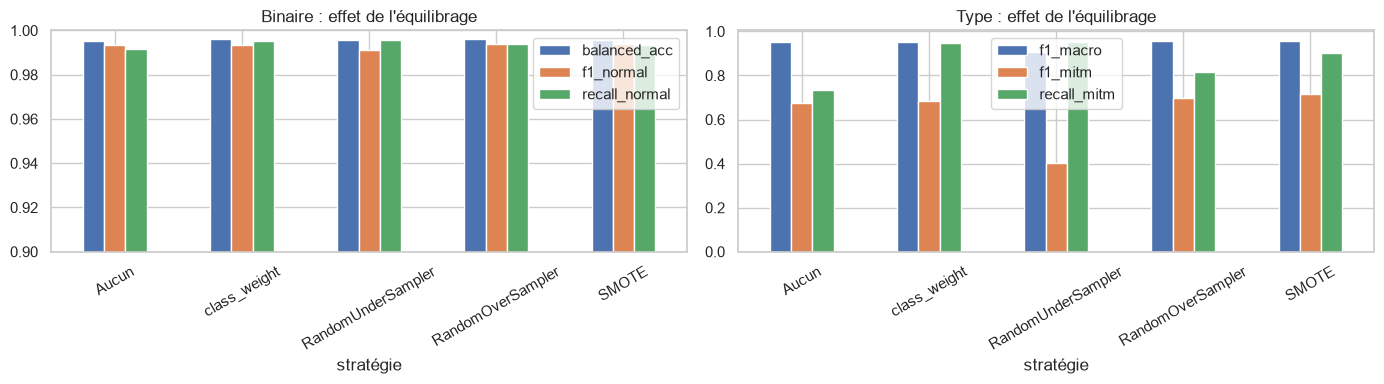

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
probe_bin[["balanced_acc", "f1_normal", "recall_normal"]].plot(kind="bar", ax=axes[0]); axes[0].set_title("Binaire : effet de l'équilibrage"); axes[0].set_ylim(.9, 1)
probe_type[["f1_macro", "f1_mitm", "recall_mitm"]].plot(kind="bar", ax=axes[1]); axes[1].set_title("Type : effet de l'équilibrage")
for a in axes: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); U.savefig(fig, "01_balancing_probe"); plt.show()

### 7.4 Décision
Les notebooks 02 et 03 (binaire) refont cette comparaison **avec validation croisée et réglage d'hyper-paramètres**, sur le jeu complet,
et retiennent la meilleure stratégie sur la **validation** (jamais sur le test). Les régresseurs (04, 05) utilisent des
`sample_weight` inversement proportionnels à la fréquence du type, ce qui équivaut à `class_weight` pour la régression.

## 8. Sauvegarde des artefacts

In [17]:
keep = num_cols + cat_cols
for n, X, y in [("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    X[keep].to_parquet(U.PROC_DIR / f"X_{n}.parquet"); y.to_parquet(U.PROC_DIR / f"y_{n}.parquet")
config = {"numeric_cols": num_cols, "categorical_cols": cat_cols, "type_order": U.TYPE_ORDER, "random_state": U.RANDOM_STATE,
          "split_sizes": {"train": len(X_train), "valid": len(X_valid), "test": len(X_test)},
          "removed_columns": {**drop_reason, **removed}}
(U.PROC_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
report.update(config["split_sizes"] | {"n_features": len(keep), "balancing_probe_label": probe_bin.round(4).to_dict("index"),
                                        "balancing_probe_type": probe_type.round(4).to_dict("index")})
U.save_result("prep", report)
print(f"{len(keep)} variables finales ({len(num_cols)} numériques, {len(cat_cols)} catégorielles)")
print("Numériques :", num_cols); print("Catégorielles :", cat_cols)
print("Fichiers :", sorted(p.name for p in U.PROC_DIR.iterdir()))

33 variables finales (24 numériques, 9 catégorielles)
Numériques : ['src_port', 'dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dns_qclass', 'dns_rcode', 'http_status_code', 'has_weird', 'total_bytes', 'total_pkts', 'bytes_ratio', 'pkts_ratio', 'bytes_per_sec', 'pkts_per_sec', 'ip_overhead_src', 'ip_overhead_dst', 'same_ports', 'src_internal', 'dst_internal']
Catégorielles : ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'src_port_bucket', 'dst_port_bucket']
Fichiers : ['X_test.parquet', 'X_train.parquet', 'X_valid.parquet', 'config.json', 'y_test.parquet', 'y_train.parquet', 'y_valid.parquet']


## Résumé de la préparation

- Valeurs `-` converties en `NaN` ; colonnes presque vides remplacées par des indicateurs `has_*`.
- Doublons et conflits supprimés **avant** le split → scores non gonflés.
- Split stratifié 60/20/20 ; sélection de variables sur le train uniquement.
- `log1p` sur les variables à queue lourde, standardisation uniquement pour le SVM, one-hot avec modalité `missing`.
- Équilibrage appliqué au train seulement (étudié ici, finalisé dans les notebooks de modélisation).